<a href="https://colab.research.google.com/github/md-tanjimul-islam/Ai-ml-shohoj-coding/blob/main/Tanjimul_Islam_Project_01.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Project 01: House Price Prediction System
**Machine Learning & AI BootCamp Portfolio Milestone**  
*Instructor: Fahd*

---

## 🏠 Project Overview & Business Case
Real estate valuation has traditionally relied on manual appraisals, which are slow, subjective, and prone to human bias. In this capstone project, you will build an automated, data-driven **House Price Prediction System** capable of accurately estimating property values based on architectural dimensions, location, build quality, and property amenities.

### Objectives:
1. Conduct thorough Exploratory Data Analysis (EDA) on residential sales records (`house_price_prediction_data.csv`).
2. Engineer high-impact domain features (age, luxury indicators, space ratios).
3. Construct a production-grade Scikit-Learn preprocessing pipeline preventing data leakage.
4. Train and benchmark multiple regression architectures:
   - Baseline Mean Model (`DummyRegressor`)
   - Ordinary Least Squares Multiple Linear Regression
   - Polynomial Feature Regression
   - Regularized Regression (Ridge & Lasso)
5. Perform hyperparameter tuning to find optimal regularization strength $\alpha$.
6. Evaluate model performance using MAE, RMSE, and $R^2$, and extract top market value drivers.


---
## Student Information
- **Student Name:** *Md. Tanjimul Islam*
- **Batch:** *MLB-2*
- **Date:** *31-10-2026*


In [66]:
# Run this cell first to import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PolynomialFeatures
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

sns.set_theme(style="whitegrid")
print("Project libraries successfully imported!")


Project libraries successfully imported!


In [67]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


---
## Step 1: Data Ingestion & Initial Inspection
1. Load `house_price_prediction_data.csv` into a DataFrame named `df`.
2. Inspect the first 5 rows and verify the shape and data types.
3. Check for missing values across all columns.


In [68]:
data = pd.read_csv("/content/drive/MyDrive/Project-01_House_Price_Prediction_System/house_price_prediction_data.csv")
df = data.copy()
df.head()

,property_id,sqft_living,bedrooms,bathrooms,lot_size_sqft,floors,waterfront,view_score,condition_rating,grade_score,yr_built,neighborhood,price_usd
0,PROP-2001,1180,3,1.0000,5650,1.0000,0,0,3,7,1955,Suburbs,"321,950.0000"
1,PROP-2002,2570,3,2.2500,7242,2.0000,0,0,3,7,1951,Northside,"538,000.0000"
2,PROP-2003,770,2,1.0000,10000,1.0000,0,0,3,6,1933,Downtown,"280,000.0000"
3,PROP-2004,1960,4,3.0000,5000,1.0000,0,0,5,7,1965,WestEnd,"604,000.0000"
4,PROP-2005,1680,3,2.0000,8080,1.0000,0,0,3,8,1987,Suburbs,"510,000.0000"


In [69]:
df.shape , df.dtypes , df.isnull().sum()

((2500, 13),
 property_id          object
 sqft_living           int64
 bedrooms              int64
 bathrooms           float64
 lot_size_sqft         int64
 floors              float64
 waterfront            int64
 view_score            int64
 condition_rating      int64
 grade_score           int64
 yr_built              int64
 neighborhood         object
 price_usd           float64
 dtype: object,
 property_id         0
 sqft_living         0
 bedrooms            0
 bathrooms           0
 lot_size_sqft       0
 floors              0
 waterfront          0
 view_score          0
 condition_rating    0
 grade_score         0
 yr_built            0
 neighborhood        0
 price_usd           0
 dtype: int64)

---
## Step 2: Exploratory Data Analysis (EDA)
1. Examine the summary statistics of `price_usd`.
2. Plot a histogram with KDE of `price_usd` to observe distribution shape and skewness.
3. Plot a boxplot comparing prices across different `neighborhood` categories.


In [70]:
pd.set_option('display.float_format', '{:,.4f}'.format)
df["price_usd"].describe()

,price_usd
count,"2,500.0000"
mean,"589,322.3800"
std,"272,345.0298"
min,"250,000.0000"
25%,"409,000.0000"
50%,"502,000.0000"
75%,"644,000.0000"
max,"1,579,500.0000"


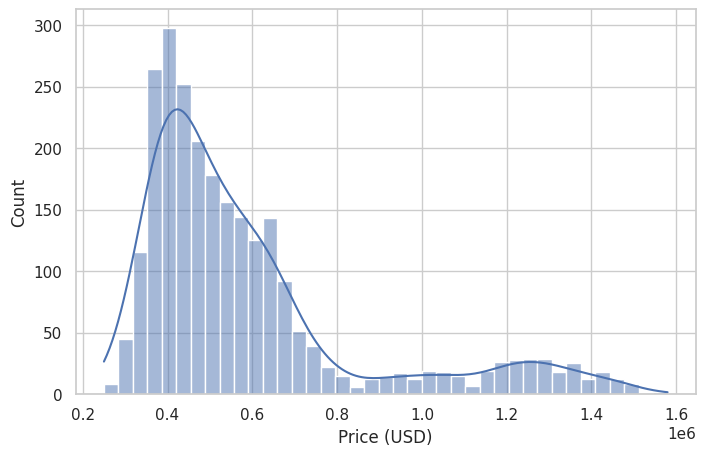

In [71]:
plt.figure(figsize=(8, 5))
sns.histplot(data=df, x="price_usd", kde=True)
plt.xlabel("Price (USD)")
plt.ylabel("Count")
plt.show()

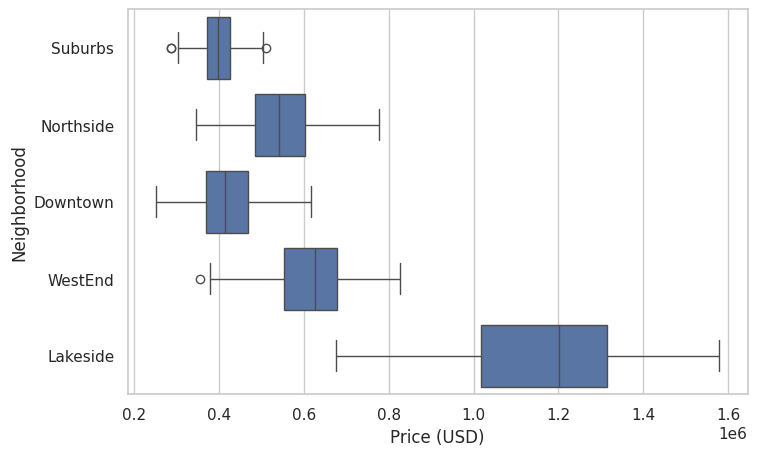

In [72]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=df, x="price_usd", y="neighborhood")
plt.xlabel("Price (USD)")
plt.ylabel("Neighborhood")
plt.show()

---
## Step 3: Domain Feature Engineering
In real estate analytics, raw features alone do not tell the whole story.
1. Create `property_age`: Number of years since construction relative to `2024` ($2024 - \text{yr\_built}$).
2. Create `bath_to_bed_ratio`: Ratio of bathrooms to bedrooms ($\frac{\text{bathrooms}}{\text{bedrooms}}$).
3. Create a binary indicator `is_luxury`: $1$ if `waterfront == 1` OR `grade_score >= 10`, else $0$.
4. Display the first 5 rows of these newly created features.


In [73]:
df["property_age"] = 2024-df["yr_built"]
df["bath_to_bed_ratio"] = df["bathrooms"]/df["bedrooms"]
df["is_luxury"] = ((df["waterfront"]==1)|(df["grade_score"]>=10)).astype(int)

df[["property_age","bath_to_bed_ratio","is_luxury"]].head()

,property_age,bath_to_bed_ratio,is_luxury
0,69,0.3333,0
1,73,0.7500,0
2,91,0.5000,0
3,59,0.7500,0
4,37,0.6667,0


---
## Step 4: Preprocessing Pipeline Construction
1. Define feature matrix `X` and target `y` (`price_usd`). Drop `property_id` and `price_usd` from `X`.
2. Identify numerical columns and categorical columns:
   - Numerical: `['sqft_living', 'bedrooms', 'bathrooms', 'lot_size_sqft', 'floors', 'waterfront', 'view_score', 'condition_rating', 'grade_score', 'property_age', 'bath_to_bed_ratio', 'is_luxury']`
   - Categorical: `['neighborhood']`
3. Build a `ColumnTransformer` named `preprocessor`:
   - Standardize numerical features with `StandardScaler()`.
   - One-hot encode `neighborhood` with `OneHotEncoder(drop='first', sparse_output=False)`.
4. Perform an **80/20 train-test split** using `train_test_split(X, y, test_size=0.20, random_state=42)`.


In [74]:
y = df["price_usd"]
X = df.drop(columns=["property_id","price_usd"])

numerical = ['sqft_living','bedrooms','bathrooms','lot_size_sqft','floors',
             'waterfront','view_score','condition_rating','grade_score',
             'property_age','bath_to_bed_ratio','is_luxury']
categorical = ['neighborhood']

preprocessor = ColumnTransformer(transformers=[
        ("num", StandardScaler(),numerical),
        ("cat", OneHotEncoder(drop='first',sparse_output=False),categorical)
    ]
)

X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.20,random_state=42)



In [75]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(2000, 14)
(500, 14)
(2000,)
(500,)


---
## Step 5: Model Training & Experimentation
Train 4 distinct regression architectures inside clean Scikit-Learn pipelines:
1. **Model 1: Baseline Dummy Regressor** (`DummyRegressor(strategy='mean')`)
2. **Model 2: OLS Linear Regression** (`LinearRegression()`)
3. **Model 3: Ridge Regression** (`Ridge(alpha=10.0)`)
4. **Model 4: Lasso Regression** (`Lasso(alpha=100.0)`)


In [76]:
dummy_model = Pipeline(steps=[('preprocessor',preprocessor),('regressor',DummyRegressor(strategy='mean'))])

dummy_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['sqft_living', 'bedrooms',
                                                   'bathrooms', 'lot_size_sqft',
                                                   'floors', 'waterfront',
                                                   'view_score',
                                                   'condition_rating',
                                                   'grade_score',
                                                   'property_age',
                                                   'bath_to_bed_ratio',
                                                   'is_luxury']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['neighborhood'])])),
                ('regressor', DummyRegressor())])

In [77]:
linear_model = Pipeline(steps=[('preprocessor', preprocessor),('regressor', LinearRegression())])

linear_model.fit(X_train, y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['sqft_living', 'bedrooms',
                                                   'bathrooms', 'lot_size_sqft',
                                                   'floors', 'waterfront',
                                                   'view_score',
                                                   'condition_rating',
                                                   'grade_score',
                                                   'property_age',
                                                   'bath_to_bed_ratio',
                                                   'is_luxury']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['neighborhood'])])),
                ('regressor', LinearRegression())])

In [78]:
ridge_model = Pipeline(steps=[('preprocessor',preprocessor),('regressor',Ridge(alpha=10.0))])

ridge_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['sqft_living', 'bedrooms',
                                                   'bathrooms', 'lot_size_sqft',
                                                   'floors', 'waterfront',
                                                   'view_score',
                                                   'condition_rating',
                                                   'grade_score',
                                                   'property_age',
                                                   'bath_to_bed_ratio',
                                                   'is_luxury']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['neighborhood'])])),
                ('regressor', Ridge(alpha=10.0))])

In [79]:
lasso_model = Pipeline(steps=[('preprocessor',preprocessor),('regressor',Lasso(alpha=100.0))])

lasso_model.fit(X_train,y_train)

Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('num', StandardScaler(),
                                                  ['sqft_living', 'bedrooms',
                                                   'bathrooms', 'lot_size_sqft',
                                                   'floors', 'waterfront',
                                                   'view_score',
                                                   'condition_rating',
                                                   'grade_score',
                                                   'property_age',
                                                   'bath_to_bed_ratio',
                                                   'is_luxury']),
                                                 ('cat',
                                                  OneHotEncoder(drop='first',
                                                                sparse_output=False),
                                                  ['neighborhood'])])),
                ('regressor', Lasso(alpha=100.0))])

---
## Step 6: Model Evaluation & Comparative Benchmark
1. For each model, generate predictions on the holdout test set (`X_test`).
2. Calculate **MAE**, **RMSE**, and **$R^2$ Score** on the test set.
3. Consolidate results into a clean comparative DataFrame named `benchmark_df` and display it.


In [80]:
dummy_predict = dummy_model.predict(X_test)
linear_predict = linear_model.predict(X_test)
ridge_predict = ridge_model.predict(X_test)
lasso_predict = lasso_model.predict(X_test)
dummy_mae = mean_absolute_error(y_test, dummy_predict)
dummy_rmse = np.sqrt(mean_squared_error(y_test, dummy_predict))
dummy_r2 = r2_score(y_test, dummy_predict)
linear_mae = mean_absolute_error(y_test, linear_predict)
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_predict))
linear_r2 = r2_score(y_test, linear_predict)
ridge_mae = mean_absolute_error(y_test, ridge_predict)
ridge_rmse = np.sqrt(mean_squared_error(y_test, ridge_predict))
ridge_r2 = r2_score(y_test, ridge_predict)
lasso_mae = mean_absolute_error(y_test, lasso_predict)
lasso_rmse = np.sqrt(mean_squared_error(y_test, lasso_predict))
lasso_r2 = r2_score(y_test, lasso_predict)

In [81]:
benchmark_df = pd.DataFrame({
    'Model' : ['Dummy Regressor', 'Linear Regression'],
    'MAE' : [dummy_mae, linear_mae],
    'RMSE' : [dummy_rmse, linear_rmse],
    'R2' : [dummy_r2, linear_r2]
})
benchmark_df

,Model,MAE,RMSE,R2
0,Dummy Regressor,"197,459.0636","279,889.8622",-0.0010
1,Linear Regression,"21,912.1634","27,734.4813",0.9902


---
## Step 7: Hyperparameter Tuning for Regularization
Use `GridSearchCV` on the Ridge pipeline to find the optimal regularization strength $\alpha$ from:
`param_grid = {'regressor__alpha': [0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0]}`.
1. Run 5-fold cross-validation optimizing for negative root mean squared error (`scoring='neg_root_mean_squared_error'`).
2. Print the best alpha value and the best cross-validation score.


In [82]:
param_grid = {'regressor__alpha': [0.1, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0]}
grid_search = GridSearchCV(estimator=ridge_model, param_grid=param_grid, cv=5, scoring='neg_root_mean_squared_error')
grid_search.fit(X_train, y_train)

print("Best Alpha:", grid_search.best_params_['regressor__alpha'])
print("Best CV Score:", -grid_search.best_score_)

Best Alpha: 0.1
Best CV Score: 29357.2728740106


---
## Step 8: Residual Analysis & Business Insights
1. Generate residuals ($y_{\text{test}} - \hat{y}_{\text{pred}}$) for your best tuned model.
2. Plot Actual vs. Predicted prices and the Residual plot.
3. Extract and plot the top 5 most influential positive and negative coefficients driving home valuation.


In [83]:
best_model = grid_search.best_estimator_
best_predict = best_model.predict(X_test)
residual = y_test - best_predict
residual.head()

,price_usd
1447,"-11,455.7687"
1114,"3,273.5585"
1064,"-29,531.1940"
2287,"-44,487.1545"
1537,"-78,904.2919"


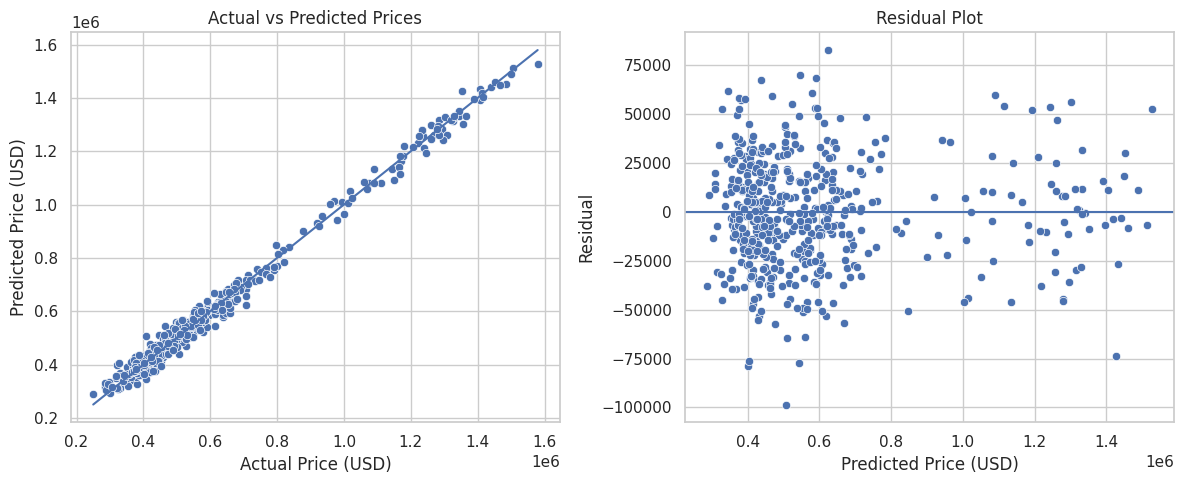

In [84]:
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.scatterplot(x=y_test, y=best_predict)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()])
plt.xlabel("Actual Price (USD)")
plt.ylabel("Predicted Price (USD)")
plt.title("Actual vs Predicted Prices")
plt.subplot(1, 2, 2)
sns.scatterplot(x=best_predict, y=residual)
plt.axhline(y=0)
plt.xlabel("Predicted Price (USD)")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.tight_layout()
plt.show()

       Feature  Coefficient
0  sqft_living  91,850.4318
6   view_score  52,939.5823
5   waterfront  51,856.4712
8  grade_score  44,367.0699
2    bathrooms  32,671.8992
                   Feature  Coefficient
9             property_age -14,404.1649
15    neighborhood_WestEnd -46,187.7052
12   neighborhood_Lakeside -54,434.1894
13  neighborhood_Northside -54,798.4314
14    neighborhood_Suburbs -89,893.6836


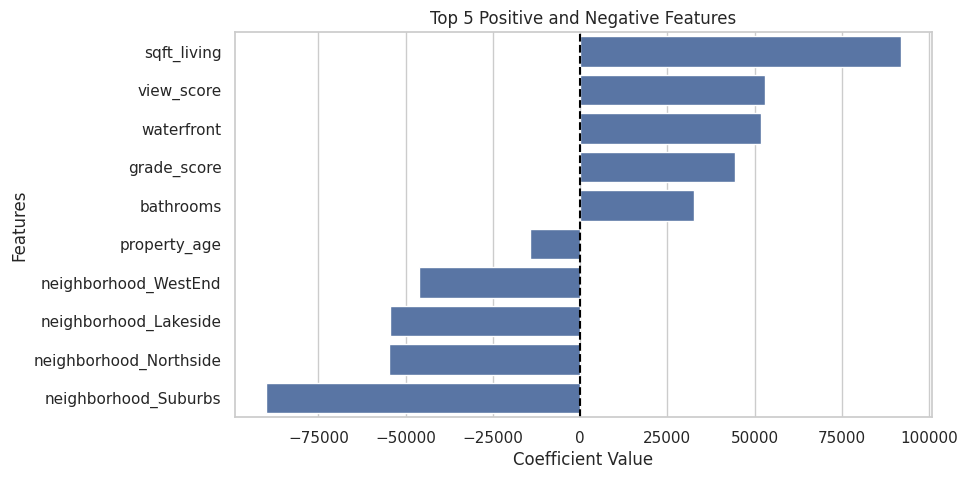

In [85]:
names = numerical + list(best_model.named_steps['preprocessor'].named_transformers_['cat'].get_feature_names_out(categorical))
coefs = best_model.named_steps['regressor'].coef_

df = pd.DataFrame({'Feature': names, 'Coefficient': coefs}).sort_values('Coefficient', ascending=False)
print(df.head(5))
print(df.tail(5))

top_features = pd.concat([top5, bot5])

plt.figure(figsize=(9, 5))
sns.barplot(data=top_features, x='Coefficient', y='Feature')
plt.axvline(0, color='black', linestyle='--')
plt.title("Top 5 Positive and Negative Features")
plt.xlabel("Coefficient Value")
plt.ylabel("Features")
plt.show()

---
### 🏆 Capstone Project Completed!
You have engineered an end-to-end Machine Learning valuation system:
- Built a leak-free preprocessing pipeline handling mixed data types.
- Compared baseline, linear, and regularized models.
- Tuned hyperparameters using cross-validation.
- Uncovered key business drivers of residential real estate valuation!
